In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('data/events.csv')
df.head()

,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
0,2019-10-01 02:25:45 UTC,view,1004785,2053013555631882655,electronics.smartphone,huawei,278.55,548829789,409ca419-adc1-43f5-8df0-5207da90a132
1,2019-10-01 02:26:59 UTC,view,1004565,2053013555631882655,electronics.smartphone,huawei,177.47,548829789,409ca419-adc1-43f5-8df0-5207da90a132
2,2019-10-01 02:27:05 UTC,view,45100030,2106075725441269865,NaN,scarlett,43.73,547152700,5e5730b4-c37b-48e8-86c0-3acc3ea515be
3,2019-10-01 02:27:59 UTC,view,45100008,2106075725441269865,NaN,NaN,10.89,547152700,5e5730b4-c37b-48e8-86c0-3acc3ea515be
4,2019-10-01 02:28:47 UTC,view,1004767,2053013555631882655,electronics.smartphone,samsung,254.82,548829789,409ca419-adc1-43f5-8df0-5207da90a132


In [3]:
df.isna().sum()

event_time            0
event_type            0
product_id            0
category_id           0
category_code    329786
brand            173670
price                 0
user_id               0
user_session          0
dtype: int64

### Work with "category_code" columns
I analyzed the category_code column and handled the missing values (329,786 rows)
* Most frequent categories: electronics.smartphone, construction.tools.light, electronics.clocks.
* 
Missing values accounted for a significant portion of the dat.* 

Categories are linked to brands (brand) and product IDs (product_id), which can be used for imputation.

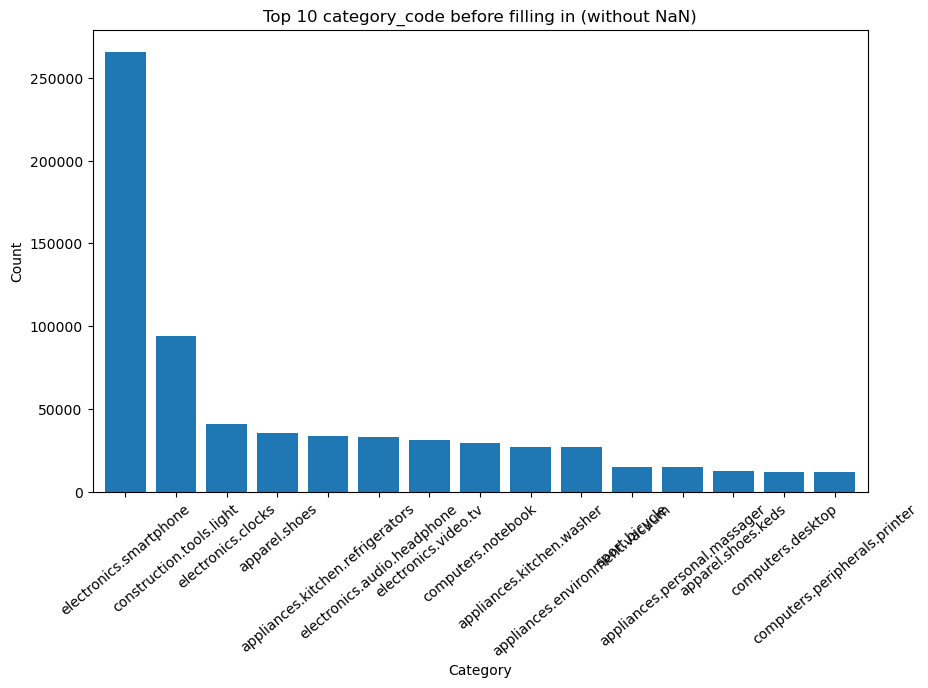

In [4]:
plt.figure(figsize=(10, 6))
df['category_code'].value_counts(dropna=True).head(15).plot(kind='bar', title='Top 10 category_code before filling in (without NaN)',width=0.8)
plt.xlabel('Category')
plt.ylabel('Count')
plt.xticks(rotation=40)
plt.show()

In [5]:
# Analysis of the category_code distribution
category_distribution = df['category_code'].value_counts(dropna=False)

# Displaying the top 10 most frequent categories
print(category_distribution.head(10))

# Output the total number of unique categories
print(f"Unique category: {df['category_code'].nunique()}")

category_code
NaN                                 329786
electronics.smartphone              265670
construction.tools.light             94074
electronics.clocks                   40940
apparel.shoes                        35713
appliances.kitchen.refrigerators     33450
electronics.audio.headphone          32938
electronics.video.tv                 31009
computers.notebook                   29337
appliances.kitchen.washer            27065
Name: count, dtype: int64
Unique category: 135


In [6]:
# Creating a dictionary to match the brand and the most frequent category
brand_category_mapping = df.dropna(subset=['category_code']).groupby('brand')['category_code'].agg(lambda x: x.mode()[0]).to_dict()

# Fill in the missing values based on the brand
df['category_code'] = df['category_code'].fillna(df['brand'].map(brand_category_mapping))

# Fill in the remaining gaps with the most frequent category
df['category_code'] = df['category_code'].fillna('electronics.smartphone')

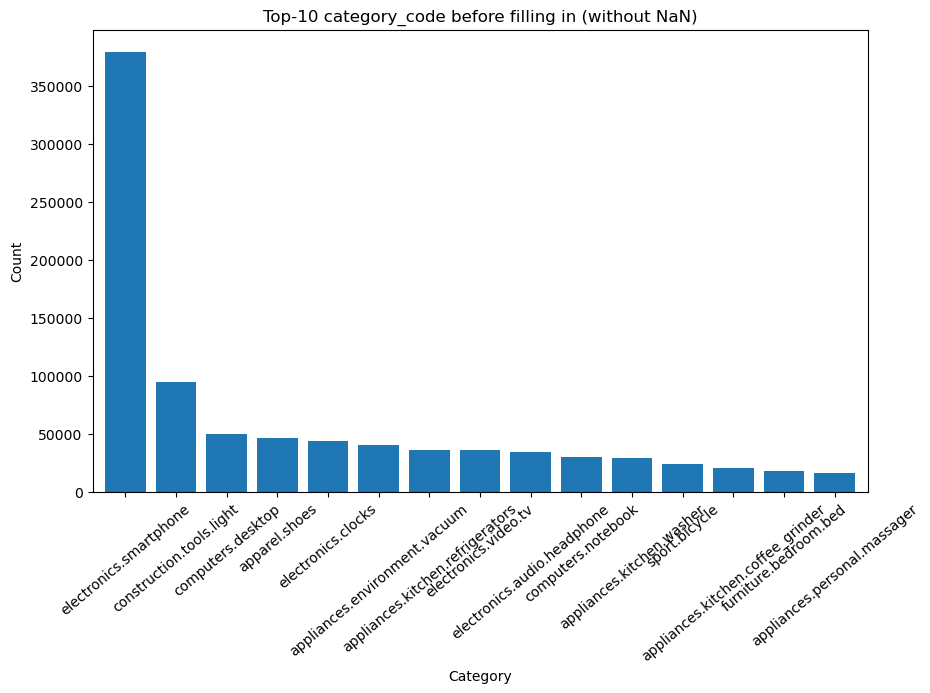

In [7]:
plt.figure(figsize=(10, 6))
df['category_code'].value_counts(dropna=True).head(15).plot(kind='bar', title='Top-10 category_code before filling in (without NaN)',width=0.8)
plt.xlabel('Category')
plt.ylabel('Count')
plt.xticks(rotation=40)
plt.show()

In [8]:
df.isnull().sum()

event_time            0
event_type            0
product_id            0
category_id           0
category_code         0
brand            173670
price                 0
user_id               0
user_session          0
dtype: int64

### Work with "brand" columns
We analyzed the brand column and handled the missing values (173,670 rows)
* Most frequent brands: samsung, apple, xiaomi.
* Missing values accounted for a significant portion of the data.
* Brands are linked to categories (category_code), which can be used for imputation.
* Filled missing values based on the product category (category_code) where possible.
* 
For remaining missing values, filled them with the most frequent brand (samsung).

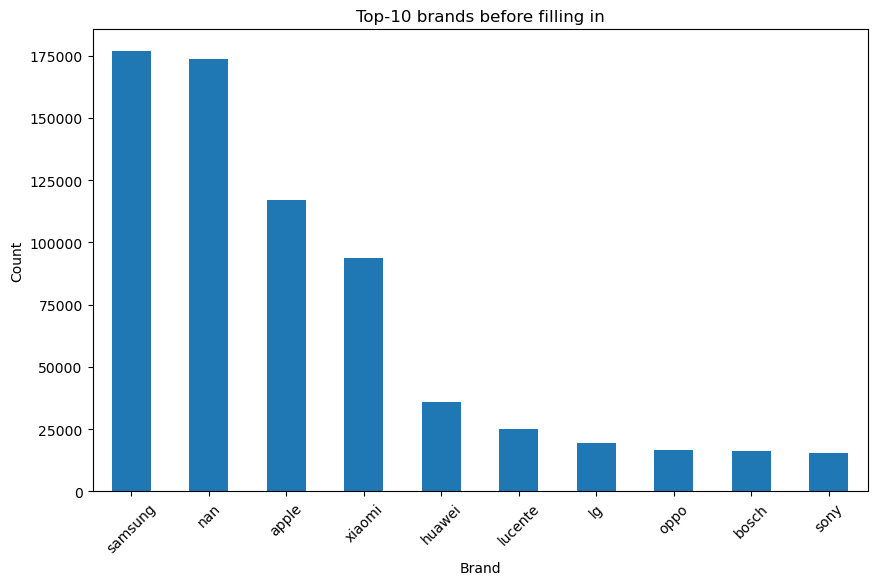

In [9]:
# Distribution before filling in
plt.figure(figsize=(10, 6))
df['brand'].value_counts(dropna=False).head(10).plot(kind='bar', title='Top-10 brands before filling in')
plt.xlabel('Brand')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

In [10]:
# Brand distribution analysis
brand_distribution = df['brand'].value_counts(dropna=False)

# Displaying the top 10 brands
print(brand_distribution.head(10))

# Output the total number of unique brands
print(f"Unique brends : {df['brand'].nunique()}")

brand
samsung    176739
NaN        173670
apple      117115
xiaomi      93708
huawei      36075
lucente     24946
lg          19349
oppo        16826
bosch       16206
sony        15293
Name: count, dtype: int64
Unique brends : 3558


In [11]:
# Creating a dictionary to match category_code and the most frequent brand
category_brand_mapping = df.dropna(subset=['brand']).groupby('category_code')['brand'].agg(lambda x: x.mode()[0]).to_dict()

# Filling in missing values based on category_code
df['brand'] = df['brand'].fillna(df['category_code'].map(category_brand_mapping))

# Fill in the remaining gaps with the most frequent brand
df['brand'] = df['brand'].fillna('samsung')

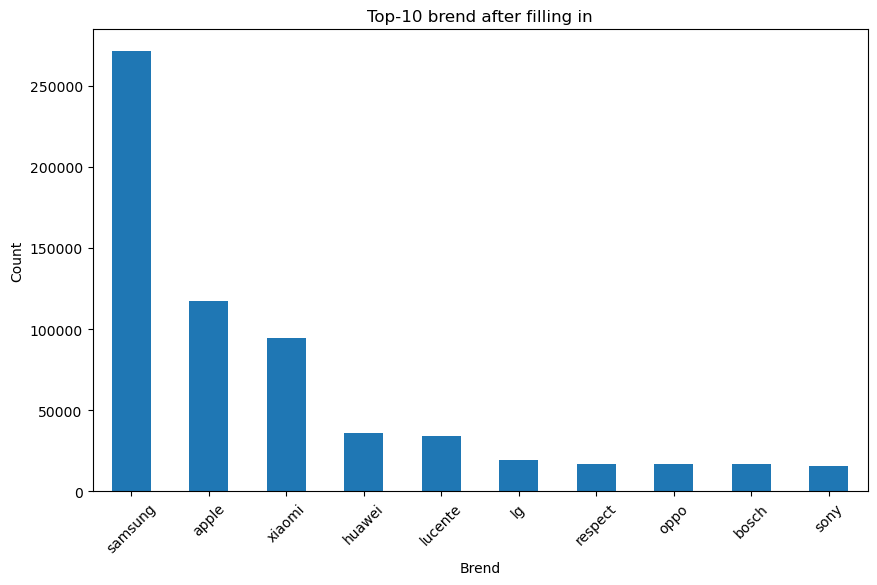

In [12]:
# Distribution after filling in
plt.figure(figsize=(10, 6))
df['brand'].value_counts().head(10).plot(kind='bar', title='Top-10 brend after filling in')
plt.xlabel('Brend')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

In [13]:
# Displaying the top 10 brands
brand_distribution = df['brand'].value_counts(dropna=False)

# Displaying the top 10 brands
print(brand_distribution.head(10))

# Output the total number of unique brands
print(f"Unique brands: {df['brand'].nunique()}")

brand
samsung    271097
apple      117432
xiaomi      94557
huawei      36075
lucente     34247
lg          19349
respect     17048
oppo        16826
bosch       16668
sony        15924
Name: count, dtype: int64
Unique brands: 3558


In [30]:
df.isna().sum()

event_time       0
event_type       0
product_id       0
category_id      0
category_code    0
brand            0
price            0
user_id          0
user_session     0
dtype: int64

In [38]:
df['event_time'] = pd.to_datetime(df['event_time'], format='%Y-%m-%d %H:%M:%S UTC')

In [43]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1307743 entries, 0 to 1307742
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype         
---  ------         --------------    -----         
 0   event_time     1307743 non-null  datetime64[ns]
 1   event_type     1307743 non-null  object        
 2   product_id     1307743 non-null  int64         
 3   category_id    1307743 non-null  int64         
 4   category_code  1307743 non-null  object        
 5   brand          1307743 non-null  object        
 6   price          1307743 non-null  float64       
 7   user_id        1307743 non-null  int64         
 8   user_session   1307743 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(3), object(4)
memory usage: 89.8+ MB
